In [2]:
print('Modelo disponible:', 'model' in globals())
print('DEVICE disponible:', 'DEVICE' in globals())

if 'model' not in globals() or 'DEVICE' not in globals():
    print('Debes ejecutar primero la práctica principal de Redes Neuronales V.')
else:
    print('Podemos continuar con fotografías reales.')

Modelo disponible: True
DEVICE disponible: True
Podemos continuar con fotografías reales.


In [6]:
import torch
import torch.nn as nn

if 'model' not in globals():
    class Encoder(nn.Module):
        def __init__(self, embedding_dim=64):
            super().__init__()
            self.conv = nn.Sequential(
                nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1)
            )
            self.fc = nn.Linear(128, embedding_dim)
        def forward(self, x):
            return self.fc(self.conv(x).flatten(1))

    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    model = Encoder(64).to(DEVICE)
    print('Encoder creado en', DEVICE)

In [4]:
import os
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
import torch.nn.functional as F

from google.colab import files

print('Librerías cargadas correctamente')

Librerías cargadas correctamente


In [7]:
ruta_base = '/content/rostros'

if os.path.exists(ruta_base):
    shutil.rmtree(ruta_base)

os.makedirs('/content/rostros/persona_01', exist_ok=True)
os.makedirs('/content/rostros/persona_02', exist_ok=True)

print('Carpetas preparadas:')
print('/content/rostros/persona_01')
print('/content/rostros/persona_02')

Carpetas preparadas:
/content/rostros/persona_01
/content/rostros/persona_02


In [8]:
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 1')

fotos_persona1 = files.upload()

if len(fotos_persona1) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona1))

for nombre, contenido in fotos_persona1.items():
    ruta = '/content/rostros/persona_01/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 1 guardadas:', len(fotos_persona1))

Seleccione EXACTAMENTE 3 fotografías de PERSONA 1


Saving images (1).jpeg to images (1).jpeg
Saving images.jpeg to images.jpeg
Saving messi 2.jpeg to messi 2.jpeg
Fotos de Persona 1 guardadas: 3


In [9]:
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 2')

fotos_persona2 = files.upload()

if len(fotos_persona2) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona2))

for nombre, contenido in fotos_persona2.items():
    ruta = '/content/rostros/persona_02/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 2 guardadas:', len(fotos_persona2))

Seleccione EXACTAMENTE 3 fotografías de PERSONA 2


Saving cristiano.jpeg to cristiano.jpeg
Saving images (2).jpeg to images (2).jpeg
Saving images (3).jpeg to images (3).jpeg
Fotos de Persona 2 guardadas: 3


In [10]:
total = 0
for carpeta, subcarpetas, archivos in os.walk('/content/rostros'):
    print('  Carpeta:', carpeta)
    for archivo in archivos:
        print('    ', archivo)
        total += 1

print('  Total de archivos encontrados:', total)

  Carpeta: /content/rostros
  Carpeta: /content/rostros/persona_02
     cristiano.jpeg
     images (2).jpeg
     images (3).jpeg
  Carpeta: /content/rostros/persona_01
     messi 2.jpeg
     images (1).jpeg
     images.jpeg
  Total de archivos encontrados: 6


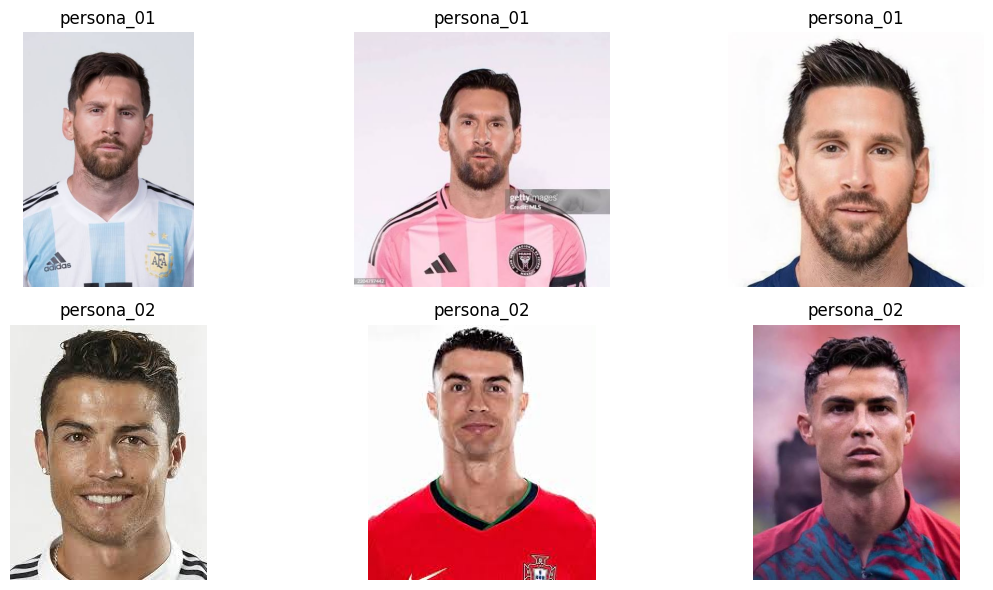

In [11]:
carpetas = [
    '/content/rostros/persona_01',
    '/content/rostros/persona_02'
]

plt.figure(figsize=(12, 6))
posicion = 1

for carpeta in carpetas:
    persona = os.path.basename(carpeta)
    for archivo in sorted(os.listdir(carpeta)):
        ruta = os.path.join(carpeta, archivo)
        imagen = Image.open(ruta).convert('RGB')
        plt.subplot(2, 3, posicion)
        plt.imshow(imagen)
        plt.title(persona)
        plt.axis('off')
        posicion += 1

plt.tight_layout()
plt.savefig('/content/evidencia_06_originales.png', dpi=120, bbox_inches='tight')
plt.show()

In [15]:
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps
import torch

def cargar_rostros(carpeta='/content/rostros', tamano=(64, 64)):
    carpeta = Path(carpeta)
    imagenes = []
    etiquetas = []
    nombres_personas = []

    # Buscar carpetas (persona_01, persona_02)
    personas = sorted([p for p in carpeta.iterdir() if p.is_dir()])

    for etiqueta, persona in enumerate(personas):
        nombres_personas.append(persona.name)
        print('Leyendo:', persona.name)

        # Leer todos los archivos dentro de la carpeta de la persona
        for archivo in sorted(persona.iterdir()):
            if not archivo.is_file():
                continue

            # Abrir la imagen, convertir a grises y ajustar tamaño
            imagen = Image.open(archivo).convert('L')
            imagen = ImageOps.fit(imagen, tamano)
            imagen = np.array(imagen, dtype=np.uint8)

            imagenes.append(imagen)
            etiquetas.append(etiqueta)

    # Convertir a tensores de PyTorch
    Xr = torch.tensor(np.stack(imagenes), dtype=torch.float32)
    Xr = Xr.unsqueeze(1) / 255.0  # Añadir canal y normalizar
    yr = torch.tensor(etiquetas, dtype=torch.long)

    return Xr, yr, nombres_personas

In [16]:
Xr, yr, nombres = cargar_rostros('/content/rostros')

print('Personas encontradas:', nombres)
print('Forma de las imágenes:', Xr.shape)
print('Etiquetas:', yr)

Leyendo: persona_01
Leyendo: persona_02
Personas encontradas: ['persona_01', 'persona_02']
Forma de las imágenes: torch.Size([6, 1, 64, 64])
Etiquetas: tensor([0, 0, 0, 1, 1, 1])


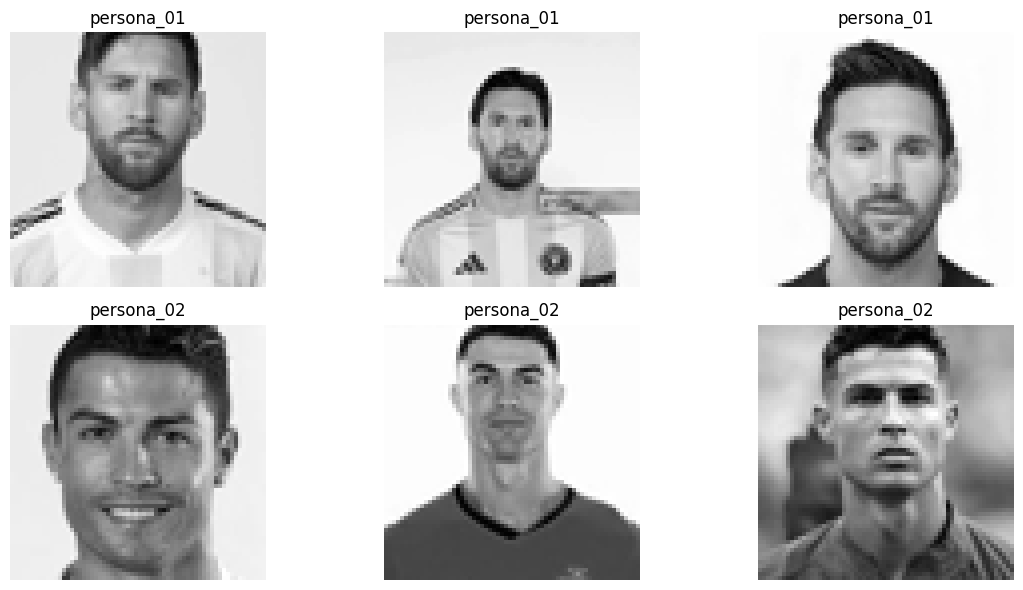

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
for i in range(len(Xr)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(Xr[i].squeeze(), cmap='gray')
    plt.title(nombres[yr[i].item()])
    plt.axis('off')

plt.tight_layout()
plt.savefig('/content/evidencia_10_preprocesadas.png', dpi=120, bbox_inches='tight')
plt.show()

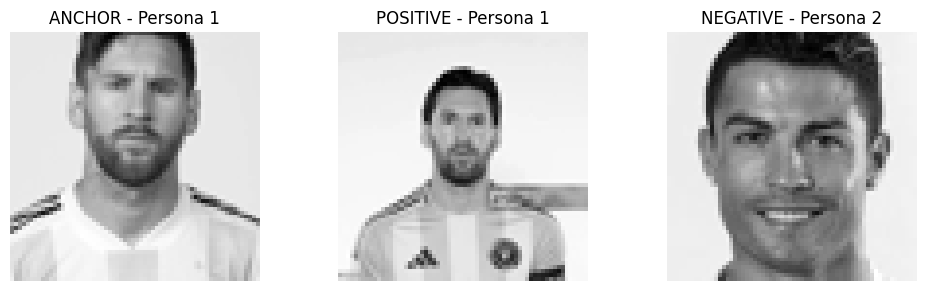

In [19]:
anchor = Xr[0]     # Messi
positive = Xr[1]   # Messi
negative = Xr[3]   # Cristiano

# Graficar
plt.figure(figsize=(10, 3))
plt.subplot(1, 3, 1)
plt.imshow(anchor.squeeze(), cmap='gray')
plt.title('ANCHOR - Persona 1')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(positive.squeeze(), cmap='gray')
plt.title('POSITIVE - Persona 1')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(negative.squeeze(), cmap='gray')
plt.title('NEGATIVE - Persona 2')
plt.axis('off')

plt.tight_layout()
plt.savefig('/content/evidencia_12_triplete.png', dpi=120, bbox_inches='tight')
plt.show()

In [25]:
print('Primeros 10 valores del Anchor:')
print(embedding_anchor[0][:10])

print('Primeros 10 valores del Positive:')
print(embedding_positive[0][:10])

print('Primeros 10 valores del Negative:')
print(embedding_negative[0][:10])

Primeros 10 valores del Anchor:
tensor([-0.0523, -0.0671,  0.0129, -0.0357,  0.0576, -0.0755, -0.0377, -0.0774,
        -0.0305, -0.0729])
Primeros 10 valores del Positive:
tensor([-0.0537, -0.0668,  0.0137, -0.0362,  0.0567, -0.0755, -0.0373, -0.0781,
        -0.0300, -0.0732])
Primeros 10 valores del Negative:
tensor([-0.0513, -0.0670,  0.0132, -0.0354,  0.0580, -0.0754, -0.0385, -0.0772,
        -0.0311, -0.0739])


In [27]:
embedding_anchor_norm = F.normalize(embedding_anchor, p=2, dim=1)
embedding_positive_norm = F.normalize(embedding_positive, p=2, dim=1)
embedding_negative_norm = F.normalize(embedding_negative, p=2, dim=1)

print('Embeddings normalizados correctamente')

Embeddings normalizados correctamente


In [28]:
distancia_AP = torch.dist(embedding_anchor_norm, embedding_positive_norm).item()
distancia_AN = torch.dist(embedding_anchor_norm, embedding_negative_norm).item()

print('Distancia misma persona:', round(distancia_AP, 4))
print('Distancia personas diferentes:', round(distancia_AN, 4))

Distancia misma persona: 0.0156
Distancia personas diferentes: 0.0167


In [29]:
if distancia_AP < distancia_AN:
    print('RESULTADO:')
    print('La red acerca correctamente las imágenes de la misma persona.')
else:
    print('RESULTADO:')
    print('La red NO logró separar correctamente estas fotografías.')

RESULTADO:
La red acerca correctamente las imágenes de la misma persona.


In [30]:
similitud_AP = F.cosine_similarity(embedding_anchor_norm, embedding_positive_norm).item()
similitud_AN = F.cosine_similarity(embedding_anchor_norm, embedding_negative_norm).item()

print('Similitud misma persona:', round(similitud_AP, 4))
print('Similitud personas diferentes:', round(similitud_AN, 4))

Similitud misma persona: 0.9999
Similitud personas diferentes: 0.9999


In [31]:
model.eval()
with torch.no_grad():
    embeddings = model(Xr.to(DEVICE))
    embeddings = F.normalize(embeddings, p=2, dim=1)

print('Embeddings generados correctamente')
print('Tamaño:', embeddings.shape)

Embeddings generados correctamente
Tamaño: torch.Size([6, 64])


In [36]:
indices_p1 = torch.where(yr == 0)[0]
indices_p2 = torch.where(yr == 1)[0]

print('Fotos Persona 1:', indices_p1)
print('Fotos Persona 2:', indices_p2)

Fotos Persona 1: tensor([0, 1, 2])
Fotos Persona 2: tensor([3, 4, 5])


In [37]:
referencias_p1 = embeddings[indices_p1[:2]]
prototipo_p1 = referencias_p1.mean(dim=0, keepdim=True)
prototipo_p1 = F.normalize(prototipo_p1, p=2, dim=1)

print('Prototipo Persona 1:', prototipo_p1.shape)

Prototipo Persona 1: torch.Size([1, 64])


In [33]:
referencias_p2 = embeddings[indices_p2[:2]]
prototipo_p2 = referencias_p2.mean(dim=0, keepdim=True)
prototipo_p2 = F.normalize(prototipo_p2, p=2, dim=1)

print('Prototipo Persona 2:', prototipo_p2.shape)

Prototipo Persona 2: torch.Size([1, 64])


In [38]:
consulta_p1 = embeddings[indices_p1[2]].unsqueeze(0)

sim_p1_p1 = F.cosine_similarity(consulta_p1, prototipo_p1).item()
sim_p1_p2 = F.cosine_similarity(consulta_p1, prototipo_p2).item()

print('FOTO REAL: Persona 1')
print('Similitud con Persona 1:', round(sim_p1_p1, 4))
print('Similitud con Persona 2:', round(sim_p1_p2, 4))

if sim_p1_p1 > sim_p1_p2:
    prediccion_p1 = 'Persona 1'
else:
    prediccion_p1 = 'Persona 2'

print('Predicción:', prediccion_p1)

FOTO REAL: Persona 1
Similitud con Persona 1: 0.9999
Similitud con Persona 2: 0.9997
Predicción: Persona 1


In [39]:
consulta_p2 = embeddings[indices_p2[2]].unsqueeze(0)

sim_p2_p1 = F.cosine_similarity(consulta_p2, prototipo_p1).item()
sim_p2_p2 = F.cosine_similarity(consulta_p2, prototipo_p2).item()

print('FOTO REAL: Persona 2')
print('Similitud con Persona 1:', round(sim_p2_p1, 4))
print('Similitud con Persona 2:', round(sim_p2_p2, 4))

if sim_p2_p2 > sim_p2_p1:
    prediccion_p2 = 'Persona 2'
else:
    prediccion_p2 = 'Persona 1'

print('Predicción:', prediccion_p2)

FOTO REAL: Persona 2
Similitud con Persona 1: 0.9987
Similitud con Persona 2: 0.9994
Predicción: Persona 2


In [40]:
print('=' * 45)
print('PRUEBA FEW-SHOT')
print('=' * 45)

print('CASO 1')
print('Real: Persona 1')
print('Predicción:', prediccion_p1)
print('Resultado:', 'CORRECTO' if prediccion_p1 == 'Persona 1' else 'INCORRECTO')

print('CASO 2')
print('Real: Persona 2')
print('Predicción:', prediccion_p2)
print('Resultado:', 'CORRECTO' if prediccion_p2 == 'Persona 2' else 'INCORRECTO')

PRUEBA FEW-SHOT
CASO 1
Real: Persona 1
Predicción: Persona 1
Resultado: CORRECTO
CASO 2
Real: Persona 2
Predicción: Persona 2
Resultado: CORRECTO


In [41]:
aciertos = 0
if prediccion_p1 == 'Persona 1':
    aciertos += 1
if prediccion_p2 == 'Persona 2':
    aciertos += 1

precision = aciertos / 2

print('Aciertos:', aciertos, 'de 2')
print('Precisión:', round(precision * 100, 2), '%')

Aciertos: 2 de 2
Precisión: 100.0 %


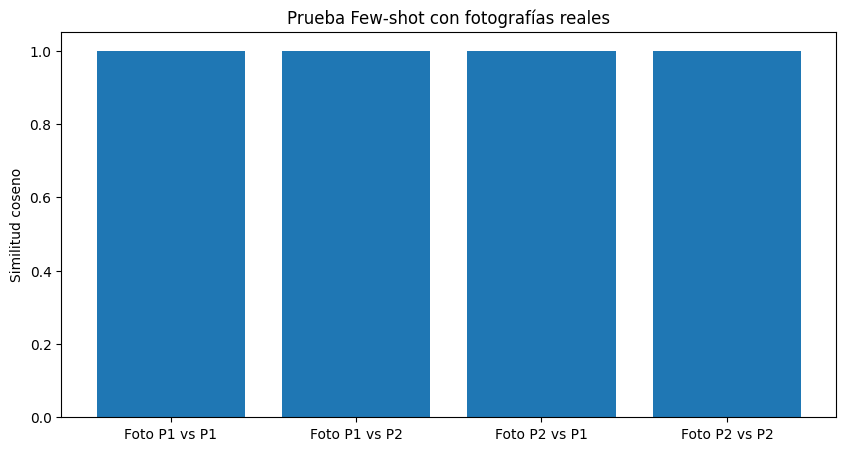

In [42]:
valores = [sim_p1_p1, sim_p1_p2, sim_p2_p1, sim_p2_p2]
nombres_grafica = [
    'Foto P1 vs P1',
    'Foto P1 vs P2',
    'Foto P2 vs P1',
    'Foto P2 vs P2'
]

plt.figure(figsize=(10, 5))
plt.bar(nombres_grafica, valores)
plt.ylabel('Similitud coseno')
plt.title('Prueba Few-shot con fotografías reales')
plt.savefig('/content/evidencia_27_fewshot.png', dpi=120, bbox_inches='tight')
plt.show()

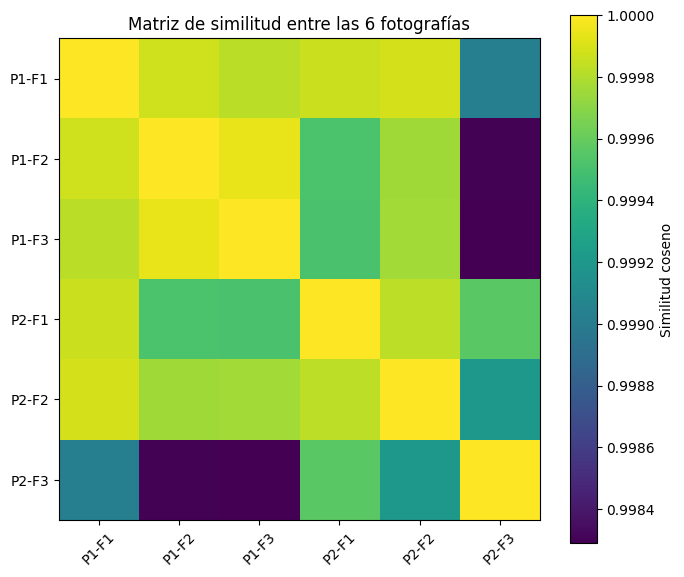

In [43]:
matriz = embeddings @ embeddings.T
matriz_np = matriz.detach().cpu().numpy()

plt.figure(figsize=(7, 6))
plt.imshow(matriz_np)
plt.colorbar(label='Similitud coseno')

etiquetas = ['P1-F1', 'P1-F2', 'P1-F3', 'P2-F1', 'P2-F2', 'P2-F3']
plt.xticks(range(6), etiquetas, rotation=45)
plt.yticks(range(6), etiquetas)
plt.title('Matriz de similitud entre las 6 fotografías')
plt.tight_layout()
plt.savefig('/content/evidencia_28_matriz.png', dpi=120, bbox_inches='tight')
plt.show()